In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

from telegram_scraper import study, viz
from telegram_scraper.study import CHANNELS, CHANNEL_ORDER, SHORT_NAMES, WINDOW
from telegram_scraper.analysis import stats

viz.apply_style()
np.random.seed(study.SEED)
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
posts = study.load_posts()
events = study.verified_events(posts)
f"{len(posts):,} posts from {posts['channel_slug'].nunique()} channels, {posts['timestamp'].min():%Y-%m-%d} to {posts['timestamp'].max():%Y-%m-%d}"

'12,221 posts from 6 channels, 2026-02-28 to 2026-04-17'

# 02 · Tempo: who posts how much, and when

> **Question.** How much more does Press TV post than the other channels, and is that a state-vs-private pattern?
>
> **Answer.** Press TV posts 136 times a day (95% CI 131-142): 4.1x IRNA, 4.7x the IDF, 5.2x JBN, 10.7x ToI and 12.0x ILTV over the full window, and the first-pass "6x ILTV, 6x JBN, 15x ToI" is wrong for ILTV (18-21x in the old article's windows) and for ToI (11x).

## 1. How much does each channel post?

Posts per **UTC calendar day** over the full window (28 Feb - 17 Apr, 49 days), zero-post days included. Confidence intervals come from resampling days with replacement (5,000 bootstrap draws, fixed seed), so they reflect how much each channel's output varies from day to day.

,channel_slug,n_posts,days,posts_per_day,ci_low,ci_high,channel
0,presstv,6683,49,136.39,130.90,142.20,Press TV
1,irna-en,1637,49,33.41,29.02,38.08,IRNA
2,idfofficial,1429,49,29.16,25.63,32.71,IDF
3,iltvnews,556,49,11.35,8.35,15.27,ILTV
4,thetimesofisrael2022,622,49,12.69,11.24,14.22,ToI
5,jewishbreakingnewstelegram,1294,49,26.41,22.41,31.02,JBN


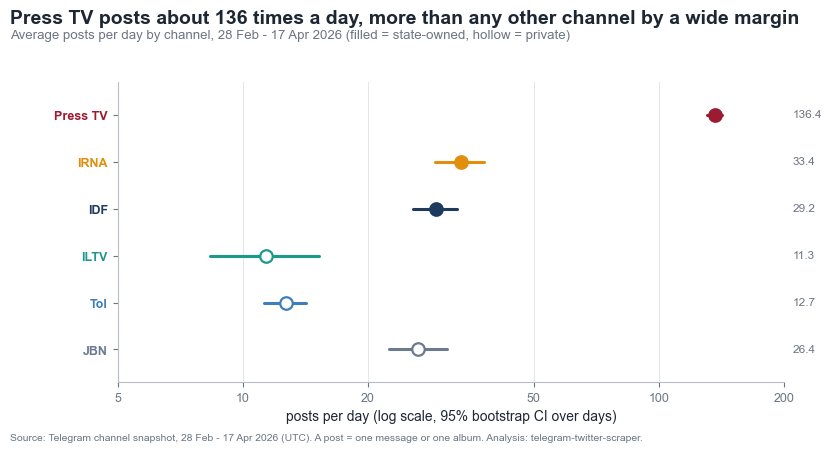

In [2]:
N_BOOT = 5000
rates = stats.daily_rate_ci(posts, start=WINDOW[0], end=WINDOW[1], n_boot=N_BOOT, seed=study.SEED)
rates = rates.set_index("channel_slug").reindex(CHANNEL_ORDER).reset_index()
rates["channel"] = rates["channel_slug"].map(SHORT_NAMES)
display(rates.round(2))

fig, ax = plt.subplots(figsize=(8.6, 3.9))
viz.dot_whisker(ax, rates, label_col="channel", est_col="posts_per_day", lo_col="ci_low", hi_col="ci_high",
                log=True, xlabel="posts per day (log scale, 95% bootstrap CI over days)", value_fmt="{:.1f}")
ax.set_xticks([5, 10, 20, 50, 100, 200]); ax.set_xticklabels(["5", "10", "20", "50", "100", "200"]); ax.minorticks_off()
pt = rates.set_index("channel_slug").loc["presstv"]
viz.headline(fig, f"Press TV posts about {pt['posts_per_day']:.0f} times a day, more than any other channel by a wide margin",
             "Average posts per day by channel, 28 Feb - 17 Apr 2026 (filled = state-owned, hollow = private)")
viz.done(fig, "02_rates_full", rates)

**Reading the figure.** Press TV averages 136 posts a day (131-142), roughly four times IRNA (33; 29-38) or the IDF (29; 26-33), five times JBN (26; 22-31) and 11-12 times ToI (13; 11-14) and ILTV (11; 8-15). The state-owned Iranian broadcaster is the outlier, but the other state channels are not: IRNA (33/day) and the IDF (29/day) post at rates close to private JBN's (26/day), and ILTV and ToI, both private, post the least. Ownership alone does not sort the channels by volume; Press TV's rate is specific to Press TV.

## 2. Rate ratios: Press TV ÷ every other channel, three equal windows

The first-pass article compared channels over mismatched stretches of time. Here every ratio uses the **same UTC days for numerator and denominator**, resampling days jointly so the interval respects that busy days are busy for everyone. Three windows: the full 49 days, and the two 8-day windows (7-14 Apr and 10-17 Apr) the old article drew on. For reference the old article's claims were Press TV ≈ 6× ILTV, 6× JBN and 15× ToI.

,window,denominator,channel,days,presstv_per_day,other_per_day,ratio,ci_low,ci_high
0,full window (28 Feb-17 Apr),irna-en,IRNA,49,136.39,33.41,4.08,3.61,4.67
1,full window (28 Feb-17 Apr),idfofficial,IDF,49,136.39,29.16,4.68,4.18,5.31
2,full window (28 Feb-17 Apr),iltvnews,ILTV,49,136.39,11.35,12.02,8.98,16.41
3,full window (28 Feb-17 Apr),thetimesofisrael2022,ToI,49,136.39,12.69,10.74,9.52,12.26
4,full window (28 Feb-17 Apr),jewishbreakingnewstelegram,JBN,49,136.39,26.41,5.16,4.39,6.14
5,7-14 Apr,irna-en,IRNA,8,127.00,31.75,4.00,3.48,4.87
6,7-14 Apr,idfofficial,IDF,8,127.00,13.50,9.41,6.63,13.59
7,7-14 Apr,iltvnews,ILTV,8,127.00,6.00,21.17,14.41,37.66
8,7-14 Apr,thetimesofisrael2022,ToI,8,127.00,11.25,11.29,8.98,15.09
9,7-14 Apr,jewishbreakingnewstelegram,JBN,8,127.00,26.25,4.84,4.42,5.40


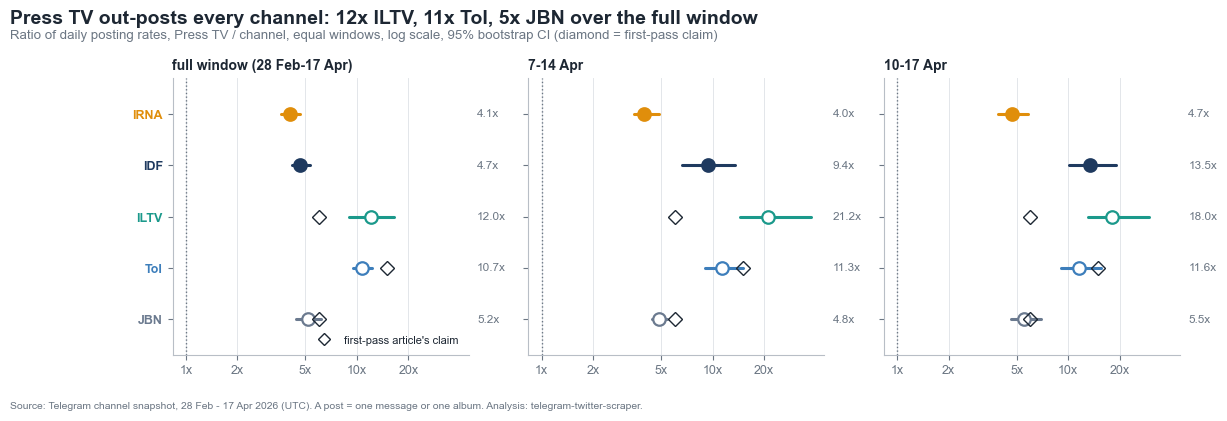

In [3]:
windows = {
    "full window (28 Feb-17 Apr)": (WINDOW[0], WINDOW[1]),
    "7-14 Apr": (pd.Timestamp("2026-04-07", tz="UTC"), pd.Timestamp("2026-04-15", tz="UTC")),
    "10-17 Apr": (pd.Timestamp("2026-04-10", tz="UTC"), pd.Timestamp("2026-04-18", tz="UTC")),
}
others = [s for s in CHANNEL_ORDER if s != "presstv"]
rows = []
for label, (start, end) in windows.items():
    for other in others:
        r = stats.rate_ratio_ci(posts, "presstv", other, start=start, end=end, n_boot=N_BOOT, seed=study.SEED)
        rows.append({"window": label, "denominator": other, "channel": SHORT_NAMES[other], "days": r["days"],
                     "presstv_per_day": r["rate_numerator"], "other_per_day": r["rate_denominator"],
                     "ratio": r["ratio"], "ci_low": r["ci_low"], "ci_high": r["ci_high"]})
ratios = pd.DataFrame(rows)
display(ratios.round(2))

OLD_CLAIM = {"iltvnews": 6, "jewishbreakingnewstelegram": 6, "thetimesofisrael2022": 15}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True, sharex=True)
for ax, (label, sub) in zip(axes, ratios.groupby("window", sort=False)):
    sub = sub.set_index("denominator").reindex(others).reset_index()
    viz.dot_whisker(ax, sub, label_col="channel", est_col="ratio", lo_col="ci_low", hi_col="ci_high",
                    slug_col="denominator", log=True, ref=1, value_fmt="{:.1f}x")
    ax.set_title(label, fontsize=10)
    for y, slug in zip(np.arange(len(others))[::-1], others):
        if slug in OLD_CLAIM:
            ax.plot([OLD_CLAIM[slug]], [y], marker="D", markersize=7, markerfacecolor="none", markeredgecolor=viz.INK, linestyle="none", zorder=4)
    ax.set_xticks([1, 2, 5, 10, 20, 50]); ax.set_xticklabels(["1x", "2x", "5x", "10x", "20x", "50x"]); ax.minorticks_off()
axes[0].plot([], [], marker="D", markerfacecolor="none", markeredgecolor=viz.INK, linestyle="none", label="first-pass article's claim")
axes[0].legend(loc="lower right", fontsize=8)
full = ratios[ratios["window"].str.startswith("full")].set_index("denominator")
viz.headline(fig, f"Press TV out-posts every channel: {full.loc['iltvnews','ratio']:.0f}x ILTV, {full.loc['thetimesofisrael2022','ratio']:.0f}x ToI, {full.loc['jewishbreakingnewstelegram','ratio']:.0f}x JBN over the full window",
             "Ratio of daily posting rates, Press TV / channel, equal windows, log scale, 95% bootstrap CI (diamond = first-pass claim)")
viz.done(fig, "02_rate_ratios", ratios)

**Reading the figure.** Over all 49 days Press TV out-posts ILTV 12.0x (9.0-16.4), ToI 10.7x (9.5-12.3), JBN 5.2x (4.4-6.1), the IDF 4.7x (4.2-5.3) and IRNA 4.1x (3.6-4.7). In the two 8-day windows the first-pass article used:

| window | ILTV | JBN | ToI | IDF | IRNA |
|---|---|---|---|---|---|
| 7-14 Apr | 21.2x (14.4-37.7) | 4.8x (4.4-5.4) | 11.3x (9.0-15.1) | 9.4x (6.6-13.6) | 4.0x (3.5-4.9) |
| 10-17 Apr | 18.0x (13.1-29.8) | 5.5x (4.6-6.9) | 11.6x (9.1-15.6) | 13.5x (10.1-19.0) | 4.7x (3.9-5.8) |

The first-pass claims (diamonds) were about right for JBN (6x) but far too low for ILTV (6x vs 18-21x in the same windows) and too high for ToI (15x vs 11x over the full window, whose interval is 9.5-12.3; the claim sits inside the wider intervals of the two 8-day windows, 9.0-15.1 and 9.1-15.6, but their point estimates are 11x). The ratios against ILTV and the IDF move a lot between windows because both channels throttled sharply after the 8 April ceasefire (see the timelines), so a ratio taken in mid-April is not a ratio for the war as a whole.

## 3. State vs. private within each country

The design has an empty cell: **there is no private Iranian channel** in the sample (Press TV and IRNA are both state), so "state vs. private" can only be tested inside Israel. Inside Iran the contrast is broadcaster vs. news agency. The Israeli comparison pools ILTV, ToI and JBN (summed posts/day) against the IDF spokesperson channel.

,comparison,numerator_per_day,denominator_per_day,ratio,ci_low,ci_high
0,Iran: Press TV / IRNA (both state),136.39,33.41,4.08,3.61,4.67
1,Israel: IDF (state) / pooled private,29.16,50.45,0.58,0.51,0.66
2,Israel: IDF / ILTV,29.16,11.35,2.57,2.01,3.34
3,Israel: IDF / ToI,29.16,12.69,2.30,2.04,2.57
4,Israel: IDF / JBN,29.16,26.41,1.10,0.93,1.33


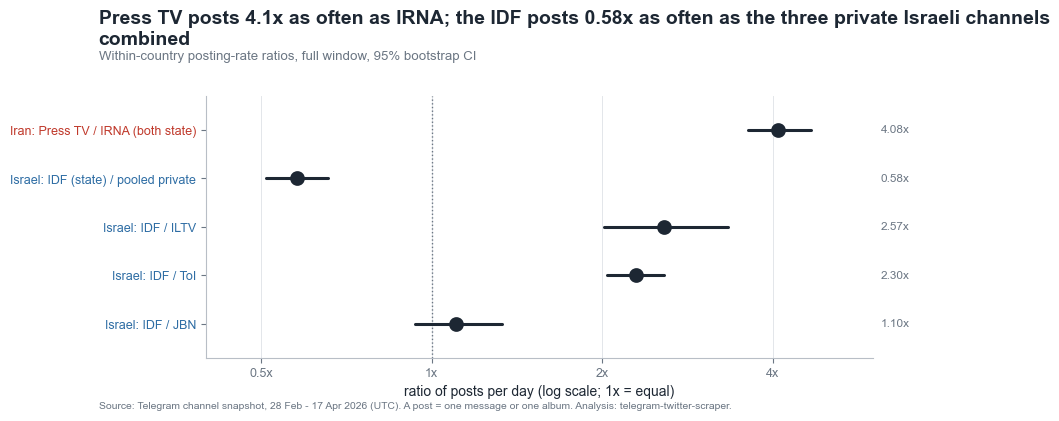

In [4]:
pooled = posts.assign(group=posts["channel_slug"].map(
    lambda s: "private Israeli (ILTV+ToI+JBN)" if s in ("iltvnews", "thetimesofisrael2022", "jewishbreakingnewstelegram") else s))
pairs = [("presstv", "irna-en", "Iran: Press TV / IRNA (both state)"),
         ("idfofficial", "private Israeli (ILTV+ToI+JBN)", "Israel: IDF (state) / pooled private"),
         ("idfofficial", "iltvnews", "Israel: IDF / ILTV"),
         ("idfofficial", "thetimesofisrael2022", "Israel: IDF / ToI"),
         ("idfofficial", "jewishbreakingnewstelegram", "Israel: IDF / JBN")]
rows = []
for num, den, label in pairs:
    frame, col = (pooled, "group") if den.startswith("private") else (posts, "channel_slug")
    r = stats.rate_ratio_ci(frame, num, den, group_col=col, start=WINDOW[0], end=WINDOW[1], n_boot=N_BOOT, seed=study.SEED)
    rows.append({"comparison": label, "numerator_per_day": r["rate_numerator"], "denominator_per_day": r["rate_denominator"],
                 "ratio": r["ratio"], "ci_low": r["ci_low"], "ci_high": r["ci_high"]})
within = pd.DataFrame(rows)
display(within.round(2))

fig, ax = plt.subplots(figsize=(8.6, 3.4))
colors = [viz.COUNTRY_COLORS["Iran"]] + [viz.COUNTRY_COLORS["Israel"]] * 4
viz.dot_whisker(ax, within.assign(channel_slug=None), label_col="comparison", est_col="ratio", lo_col="ci_low", hi_col="ci_high", slug_col=None, log=True, ref=1, value_fmt="{:.2f}x")
ax.set_xlabel("ratio of posts per day (log scale; 1x = equal)")
ax.set_xlim(0.4, 6); ax.set_xticks([0.5, 1, 2, 4]); ax.set_xticklabels(["0.5x", "1x", "2x", "4x"]); ax.minorticks_off()
for tick, color in zip(ax.get_yticklabels()[: len(colors)], colors):
    tick.set_color(color)
iran = within.iloc[0]; idf_pool = within.iloc[1]
viz.headline(fig, f"Press TV posts {iran['ratio']:.1f}x as often as IRNA; the IDF posts {idf_pool['ratio']:.2f}x as often as the three private Israeli channels combined",
             "Within-country posting-rate ratios, full window, 95% bootstrap CI")
viz.done(fig, "02_within_country", within)

**Reading the figure.** Inside Iran the two state channels differ a great deal: Press TV out-posts IRNA 4.1x (3.6-4.7), so "the state outlet" is not one posting profile. Inside Israel the state channel (the IDF, 29/day) posts *fewer* items than the three private channels combined (50/day; ratio 0.58, 0.51-0.66), 2.6x ILTV (2.0-3.3) and 2.3x ToI (2.0-2.6), and at the same rate as JBN (1.10x; 0.93-1.33, includes 1). Note the design limit again: there is no private Iranian channel, so a state-vs-private contrast inside Iran cannot be made, and the Israeli state channel is a military spokesperson, not a broadcaster.

## 4. Daily timelines with verified events

Each panel is one channel (bars = posts per day, line = 3-day centred mean). Dotted lines are the events notebook 01 verified in the text of the posts themselves.

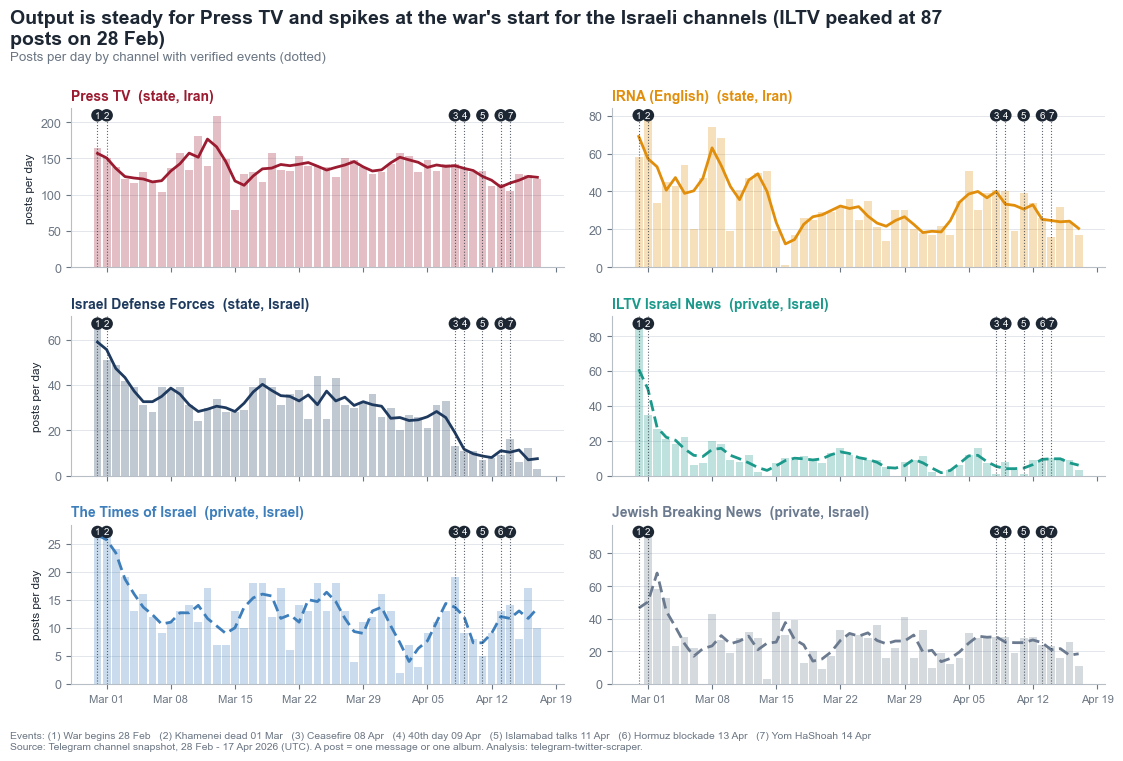

Days with fewer than 10% of the channel's median daily output (possible gaps or outages):


,date,posts,channel
0,2026-02-28 00:00:00+00:00,0,JBN
1,2026-03-07 00:00:00+00:00,0,JBN
2,2026-03-14 00:00:00+00:00,0,ILTV
3,2026-03-16 00:00:00+00:00,1,IRNA
4,2026-03-28 00:00:00+00:00,0,ILTV
5,2026-04-02 00:00:00+00:00,0,ILTV


PosixPath('/Users/lfpmb/Documents/telegram-twitter-scraper/docs/study/interactive/02_daily_posts.html')

In [5]:
daily = (posts.groupby(["date", "channel_slug"]).size().unstack(fill_value=0)
         .reindex(pd.date_range(WINDOW[0], WINDOW[1] - pd.Timedelta(days=1), freq="D", tz="UTC"), fill_value=0)
         .reindex(columns=CHANNEL_ORDER))
daily.index.name = "date"
fig = viz.timeline_small_multiples(daily, events, ncols=2)
peak = daily.idxmax()
viz.headline(fig, f"Output is steady for Press TV and spikes at the war's start for the Israeli channels (ILTV peaked at {daily['iltvnews'].max()} posts on {peak['iltvnews']:%d %b})",
             "Posts per day by channel with verified events (dotted)", y=1.04)
viz.done(fig, "02_daily_timelines", daily.reset_index().melt(id_vars="date", var_name="channel_slug", value_name="posts"), note=viz.event_key(events))

low_days = daily.where(daily < 0.1 * daily.median()).stack().astype(int).rename("posts").reset_index()
low_days.columns = ["date", "channel_slug", "posts"]
low_days["channel"] = low_days["channel_slug"].map(SHORT_NAMES)
print("Days with fewer than 10% of the channel's median daily output (possible gaps or outages):")
display(low_days.drop(columns="channel_slug"))
viz.save(viz.plotly_lines(daily, title="Daily posts per channel", subtitle="Interactive: hover for counts", events=events, ylabel="posts per day"), "02_daily_posts")

**Reading the figure.** Press TV is the steadiest channel (coefficient of variation of daily posts 0.15, between 79 and 209 posts a day) and stays at 125 posts a day after the 8 April ceasefire against 139 before it. The Israeli channels are driven by events: ILTV posted 87 times on 28 Feb and 27% of its entire 49-day output fell in the first three days (coefficient of variation 1.15); the IDF fell from 34 posts a day before 8 April to 10 afterwards (0.3x), ILTV from 13 to 6. IRNA (35 to 29), JBN (27 to 23) and ToI (13 to 11) barely moved.

Data-quality flags (table above): JBN has zero posts on 28 Feb and 7 Mar, ILTV on 14 Mar, 28 Mar and 2 Apr, and IRNA a single post on 16 Mar. These may be genuine silences, platform outages or deleted posts; the snapshot cannot say. The bootstrap intervals in this notebook resample whole days, so they absorb such gaps, but a reader should not treat any single day as complete.

## 5. When in the day do they post?

Share of each channel's posts in each hour of the day, once in UTC and once in each channel's own local time (Tehran, UTC+3:30 all period; Jerusalem, UTC+2 switching to UTC+3 on 27 Mar). A uniform channel would be a flat strip; a newsroom with day and night shifts has a visible glow.

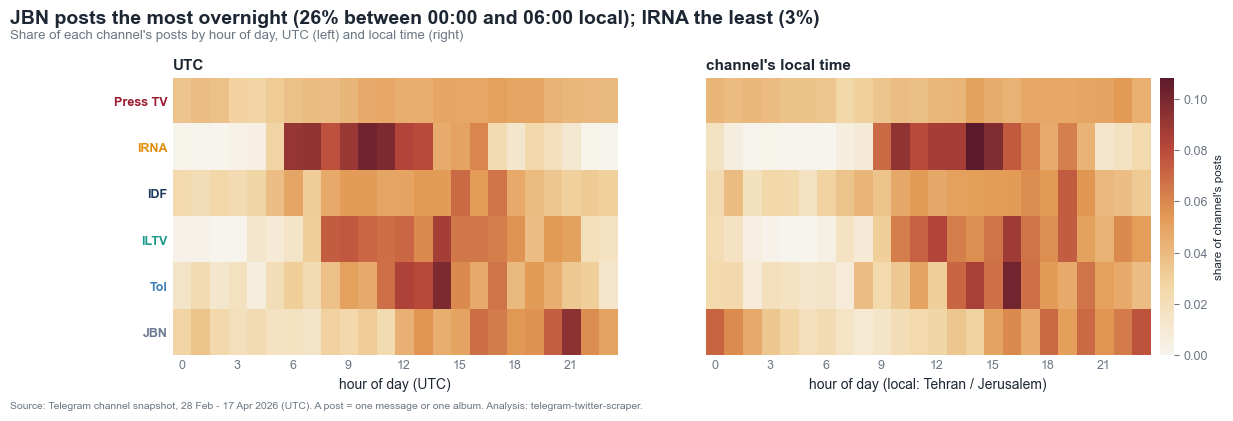

,channel,peak_hour_local,peak_share,share_00_06_local,share_08_22_local
channel_slug,,,,,
presstv,Press TV,22,0.054,0.234,0.606
irna-en,IRNA,14,0.108,0.026,0.927
idfofficial,IDF,19,0.074,0.148,0.717
iltvnews,ILTV,16,0.088,0.045,0.824
thetimesofisrael2022,ToI,16,0.101,0.106,0.786
jewishbreakingnewstelegram,JBN,23,0.077,0.259,0.562


In [6]:
local = study.add_local_time(posts)
def hour_share(col):
    t = pd.crosstab(local["channel_slug"], local[col]).reindex(index=CHANNEL_ORDER, columns=range(24), fill_value=0)
    return t.div(t.sum(axis=1), axis=0)
utc_share, local_share = hour_share("hour_utc"), hour_share("local_hour")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
vmax = max(utc_share.to_numpy().max(), local_share.to_numpy().max())
viz.heat_strips(utc_share, axes[0], xlabel="hour of day (UTC)", vmax=vmax)
im = viz.heat_strips(local_share, axes[1], xlabel="hour of day (local: Tehran / Jerusalem)", vmax=vmax)
axes[0].set_title("UTC"); axes[1].set_title("channel's local time")
cbar = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01); cbar.set_label("share of channel's posts", fontsize=8.5); cbar.outline.set_visible(False)
night = lambda t: t[[0, 1, 2, 3, 4, 5]].sum(axis=1)   # 00:00-05:59 local
night_share = night(local_share)
viz.headline(fig, f"{SHORT_NAMES[night_share.idxmax()]} posts the most overnight ({night_share.max():.0%} between 00:00 and 06:00 local); {SHORT_NAMES[night_share.idxmin()]} the least ({night_share.min():.0%})",
             "Share of each channel's posts by hour of day, UTC (left) and local time (right)")
tidy = lambda t, clock: t.rename_axis(index="channel_slug", columns="hour").stack().rename("share").reset_index().assign(clock=clock)
long = pd.concat([tidy(utc_share, "utc"), tidy(local_share, "local")], ignore_index=True)
viz.done(fig, "02_hour_rhythm", long)
rhythm = pd.DataFrame({"peak_hour_local": local_share.idxmax(axis=1), "peak_share": local_share.max(axis=1), "share_00_06_local": night_share,
                       "share_08_22_local": local_share[list(range(8, 22))].sum(axis=1)}).rename_axis("channel_slug")
rhythm.insert(0, "channel", [SHORT_NAMES[s] for s in rhythm.index])
display(rhythm.round(3))

**Reading the figure.** Press TV's posts are almost uniform across the 24 hours: its busiest local hour (22:00 Tehran) holds only 5.4% of posts against 4.2% for a perfectly flat day, and 23% of posts fall between 00:00 and 06:00 Tehran time. That is a round-the-clock operation. IRNA is the opposite: 93% of its posts fall between 08:00 and 22:00 Tehran time with a 14:00 peak (10.8%) and only 2.6% overnight, the signature of a daytime newsroom. Among the Israeli channels JBN posts the most overnight (26% between 00:00 and 06:00 Jerusalem time), the IDF 15%, ToI 11% and ILTV 4.5%. Local-time clocks are the honest comparison, which is why both clocks are shown.

## 6. An engagement lens: views per post

Views are a *different* quantity from output: they depend on how many subscribers a channel has, so they are **not** comparable as a measure of influence across channels. They are included as a lens on reach per post, and as the baseline for the media-type analysis in notebook 06. Views were read when the snapshot was taken (months after posting), so older posts have had longer to accumulate views.

,channel_slug,channel,n,median_views,ci_low,ci_high,posts_per_day,median_daily_views_per_post_x_rate
0,presstv,Press TV,6619,8049.0,8006.0,8086.0,136.4,1097785.0
1,irna-en,IRNA,1635,2586.0,2537.0,2622.0,33.4,86393.5
2,idfofficial,IDF,1429,12023.0,11860.0,12233.0,29.2,350629.9
3,iltvnews,ILTV,556,6822.0,6735.0,6925.0,11.3,77408.8
4,thetimesofisrael2022,ToI,622,5104.0,5003.0,5187.5,12.7,64789.6
5,jewishbreakingnewstelegram,JBN,1293,3935.0,3900.0,3973.0,26.4,103916.1


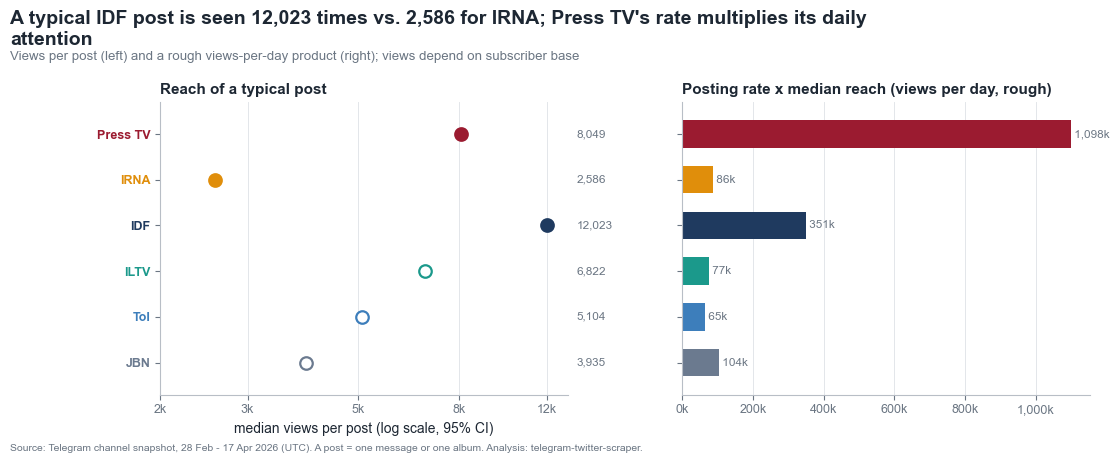

In [7]:
rows = []
for slug in CHANNEL_ORDER:
    v = posts.loc[posts["channel_slug"] == slug, "views"].astype("float")
    r = study.bootstrap_median_ci(v, n_boot=N_BOOT, seed=study.SEED)
    rows.append({"channel_slug": slug, "channel": SHORT_NAMES[slug], "n": r["n"], "median_views": r["median"], "ci_low": r["ci_low"], "ci_high": r["ci_high"],
                 "posts_per_day": float(rates.set_index("channel_slug").loc[slug, "posts_per_day"])})
views = pd.DataFrame(rows)
views["median_daily_views_per_post_x_rate"] = views["median_views"] * views["posts_per_day"]
display(views.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1], "wspace": 0.28}, sharey=True)
viz.dot_whisker(axes[0], views, label_col="channel", est_col="median_views", lo_col="ci_low", hi_col="ci_high", log=True, value_fmt="{:,.0f}", xlabel="median views per post (log scale, 95% CI)")
axes[0].set_xticks([2000, 3000, 5000, 8000, 12000]); axes[0].set_xticklabels(["2k", "3k", "5k", "8k", "12k"]); axes[0].minorticks_off()
axes[0].set_title("Reach of a typical post")
views["posts_x_median"] = views["median_views"] * views["posts_per_day"]
axes[1].barh(np.arange(len(views))[::-1], views["posts_x_median"], color=[viz.CHANNEL_COLORS[s] for s in views["channel_slug"]], height=0.6)
for y, v in zip(np.arange(len(views))[::-1], views["posts_x_median"]):
    axes[1].text(v, y, f" {v/1000:,.0f}k", va="center", fontsize=8.5, color=viz.MUTED)
axes[1].set_title("Posting rate x median reach (views per day, rough)"); axes[1].grid(axis="y", visible=False)
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
top_reach = views.sort_values("median_views").iloc[-1]; low_reach = views.sort_values("median_views").iloc[0]
viz.headline(fig, f"A typical {top_reach['channel']} post is seen {top_reach['median_views']:,.0f} times vs. {low_reach['median_views']:,.0f} for {low_reach['channel']}; Press TV's rate multiplies its daily attention",
             "Views per post (left) and a rough views-per-day product (right); views depend on subscriber base")
viz.done(fig, "02_views_per_post", views)

**Reading the figure.** The IDF's typical post is seen about 12,000 times, Press TV's about 8,000, ILTV's 6,800, ToI's 5,100, JBN's 3,900 and IRNA's 2,600. These depend on how many subscribers each channel has, so they say nothing about relative influence. What they do show is the cumulative effect of Press TV's volume: posting rate times median views gives roughly 1.1 million views a day for Press TV against 351 thousand for the IDF and 65-104 thousand for the other four. Press TV's *relative* advantage is in the number of impressions it generates, not in how well each post performs.

## 7. The 2 × 2 at a glance

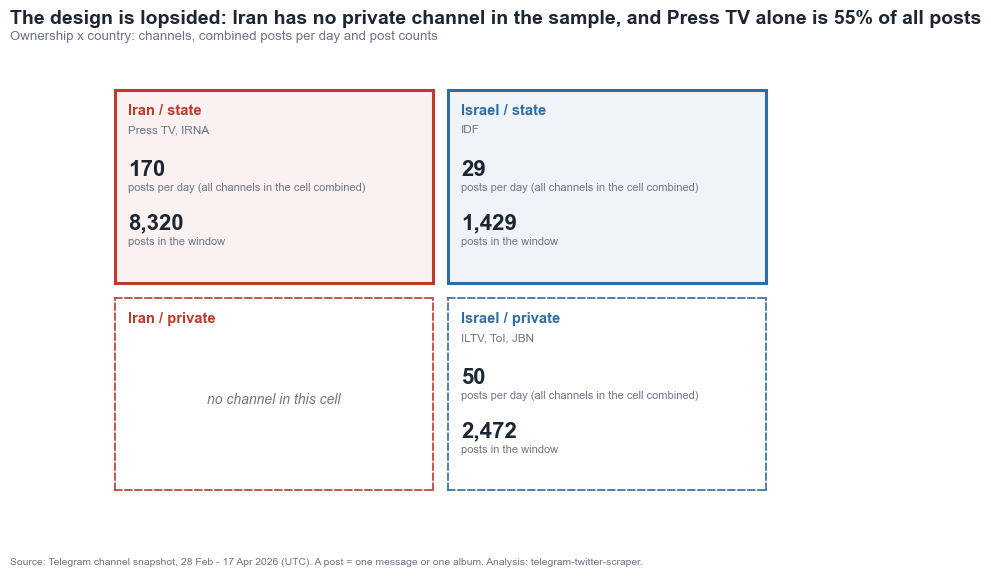

,ownership,country,channels,posts_per_day,n_posts
0,private,Israel,"ILTV, ToI, JBN",50.4,2472
1,state,Iran,"Press TV, IRNA",169.8,8320
2,state,Israel,IDF,29.2,1429


In [8]:
cells = {}
for (own, country), g in posts.groupby(["ownership", "country"]):
    slugs = [s for s in CHANNEL_ORDER if s in set(g["channel_slug"])]
    cells[(own, country)] = {"channels": slugs, "per_day": float(rates.set_index("channel_slug").loc[slugs, "posts_per_day"].sum()), "n": len(g)}
fig = plt.figure(figsize=(8.4, 5.2))
viz.quadrant_panel(fig, cells, metrics=[("per_day", "posts per day (all channels in the cell combined)", "{:,.0f}"), ("n", "posts in the window", "{:,.0f}")])
viz.headline(fig, f"The design is lopsided: Iran has no private channel in the sample, and Press TV alone is {int(posts['channel_slug'].eq('presstv').sum()) / len(posts):.0%} of all posts",
             "Ownership x country: channels, combined posts per day and post counts", y=1.0)
quad = pd.DataFrame([{"ownership": o, "country": c, "channels": ", ".join(SHORT_NAMES[s] for s in v["channels"]), "posts_per_day": v["per_day"], "n_posts": v["n"]} for (o, c), v in cells.items()])
viz.done(fig, "02_quadrant", quad)
display(quad.round(1))

In [9]:
key_ratio = lambda w, d: ratios[(ratios["window"] == w) & (ratios["denominator"] == d)].iloc[0]
_ = study.record_findings("02_tempo", {
    "n_boot": N_BOOT,
    "posts_per_day": rates.drop(columns="channel"),
    "press_tv_rate_ratios": ratios.drop(columns="channel"),
    "within_country_ratios": within,
    "first_pass_claims_vs_equal_window": {
        slug: {"claimed": OLD_CLAIM[slug], **{w: float(key_ratio(w, slug)["ratio"]) for w in windows}} for slug in OLD_CLAIM
    },
    "median_views": views[["channel_slug", "n", "median_views", "ci_low", "ci_high"]],
    "hour_rhythm_local": rhythm.drop(columns="channel").reset_index(),
    "low_output_days": low_days.drop(columns="channel"),
    "ownership_country_cells": quad,
    "verified_events": [e["key"] for e in events],
})

## What this means for the article

- **State the equal-window result**: Press TV posts 4-5x as much as IRNA, the IDF and JBN, and 11-12x as much as ToI and ILTV, over the full 49 days (intervals in the table). Do not reuse "6x / 6x / 15x".
- **Do not call volume a state-ownership effect.** Two of the three other state or state-adjacent channels (IRNA, the IDF) post at the same order of magnitude as private JBN; the outlier is one channel.
- **Describe Press TV as always-on, IRNA as daytime, the IDF and ILTV as burst-and-decay** (both fell by half or more after the ceasefire).
- **Flag what cannot be tested**: no private Iranian channel exists in the sample, the IDF is a military spokesperson, JBN's ownership is unverified.
- **Do not use view counts across channels as evidence of influence.**